# Estadísticos Descriptivos — Conjunto de Datos Depurado

Calcula estadísticos descriptivos (N, media, desv. estándar, mín., máx.) para las variables objetivo
del dataset de entrenamiento tras aplicar el filtro de depuración estándar.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path

In [2]:
BASE      = Path('../../')
DATA_PATH = BASE / 'data/processed/ifn_entrenamiento_year_agrupado_periodo_completado_2.csv'

# Variables a analizar (en el orden de la tabla)
TARGET_VARS = ['carbono_bruto4', 'carbono_bruto', 'c4', 'c', 'periodo_agrupado']

# Nombres de presentación
VAR_LABELS = {
    'carbono_bruto4'  : 'carbono\_bruto4',
    'carbono_bruto'   : 'carbono\_bruto',
    'c4'              : 'c4',
    'c'               : 'c',
    'periodo_agrupado': 'periodo\_agrupado',
}

print(f'Data: {DATA_PATH}')

Data: ../../data/processed/ifn_entrenamiento_year_agrupado_periodo_completado_2.csv


In [3]:
# Dataset se carga en cell-stats
pass

## Depuración

Para cada variable objetivo se aplica el filtro estándar:
- Valor no nulo y distinto de cero.
- Para `c4` y `c`: se excluyen filas donde `fccarb < 20` (carbono de fustales anómalos).
- Para `c4`: adicionalmente se excluyen filas donde `c` existe y `c >= c4`.

In [4]:
def _apply_training_filter(df: pd.DataFrame, var: str) -> pd.DataFrame:
    """
    Aplica exactamente el mismo filtro que los scripts de entrenamiento
    (sin el filtrado por inventario IFN2/IFN3).

    Lógica (de entrenamiento_ifn2_3_c4.py / _carbono_bruto4.py):
      1. TARGET no nulo y distinto de 0
      2. c es nulo  O  c < TARGET   (dato coherente entre periodos)
      3. ~(fccarb no nulo AND fccarb < 20)  (descarta fustales anómalos)

    Para 'c' y 'carbono_bruto' no hay scripts propios, se omite
    la condición cruzada con 'c' (que se referiría a sí misma).
    'periodo_agrupado' se calcula sobre el subconjunto de c4.
    """
    mask = df[var].notna() & (df[var] != 0)

    # Condición cruzada con 'c' solo cuando el target NO es 'c' mismo
    cross_var = 'c'
    if var != cross_var and cross_var in df.columns:
        mask = mask & (df[cross_var].isna() | (df[cross_var] < df[var]))

    # Filtro fccarb
    if 'fccarb' in df.columns:
        mask = mask & ~(df['fccarb'].notna() & (df['fccarb'] < 20))

    return df[mask]


df_raw = pd.read_csv(DATA_PATH)
print(f'Dataset bruto: {df_raw.shape[0]:,} filas x {df_raw.shape[1]} cols')

rows = []
_df_c4_filtered = None   # reutilizado para periodo_agrupado

for var in TARGET_VARS:
    if var not in df_raw.columns:
        print(f'  [SKIP] {var} — columna no encontrada')
        continue

    if var == 'periodo_agrupado':
        # Estadísticos sobre el mismo subconjunto que c4
        if _df_c4_filtered is None:
            print('  [WARN] c4 no procesado antes que periodo_agrupado')
            continue
        s = _df_c4_filtered[var].dropna()
    else:
        df_f = _apply_training_filter(df_raw, var)
        s = df_f[var]
        if var == 'c4':
            _df_c4_filtered = df_f   # guardar para periodo_agrupado

    rows.append({
        'Variable'      : var,
        'N'             : len(s),
        'Media'         : round(s.mean(), 2),
        'Desv. estándar': round(s.std(),  2),
        'Mín.'          : round(s.min(),  2),
        'Máx.'          : round(s.max(),  2),
    })
    print(f'  {var:20s}  N={len(s):,}  μ={s.mean():.2f}  σ={s.std():.2f}  [{s.min():.2f}, {s.max():.2f}]')

df_stats = pd.DataFrame(rows).set_index('Variable')
display(df_stats.style.format({
    'N': '{:,.0f}', 'Media': '{:.2f}',
    'Desv. estándar': '{:.2f}', 'Mín.': '{:.2f}', 'Máx.': '{:.2f}'
}))


Dataset bruto: 259,853 filas x 446 cols


  carbono_bruto4        N=133,119  μ=20.79  σ=35.09  [0.00, 420.50]


  carbono_bruto         N=123,563  μ=10.09  σ=26.33  [0.00, 511.31]


  c4                    N=103,790  μ=38.83  σ=47.27  [0.48, 883.46]


  c                     N=131,942  μ=29.58  σ=40.62  [0.44, 873.36]
  periodo_agrupado      N=103,785  μ=18.47  σ=6.47  [5.00, 30.00]


,N,Media,Desv. estándar,Mín.,Máx.
Variable,,,,,
carbono_bruto4,"133,119",20.79,35.09,0.00,420.50
carbono_bruto,"123,563",10.09,26.33,0.00,511.31
c4,"103,790",38.83,47.27,0.48,883.46
c,"131,942",29.58,40.62,0.44,873.36
periodo_agrupado,"103,785",18.47,6.47,5.00,30.00


In [5]:
col_headers = ['Variable', 'N', 'Mean', 'Std. dev.', 'Min.', 'Max.']
col_align   = 'lrrrrr'

lines = [
    r'\begin{table}[htbp]',
    r'  \centering',
    r'  \caption{Descriptive statistics of the cleaned dataset.}',
    r'  \label{tab:descriptivos}',
    f'  \\begin{{tabular}}{{{col_align}}}',
    r'    \toprule',
    '    ' + ' & '.join(f'\\textbf{{{h}}}' for h in col_headers) + r' \\\\',
    r'    \midrule',
]

for var, row in df_stats.iterrows():
    lbl    = VAR_LABELS.get(var, var.replace('_', r'\_'))
    n_fmt  = f'{int(row["N"]):,}'.replace(',', r'\,')
    mu_fmt = f'{row["Media"]:.2f}'
    sd_fmt = f'{row["Desv. estándar"]:.2f}'
    mn_fmt = f'{row["Mín."]:.2f}'
    mx_fmt = f'{row["Máx."]:.2f}'
    lines.append(f'    {lbl} & {n_fmt} & {mu_fmt} & {sd_fmt} & {mn_fmt} & {mx_fmt} \\\\')

lines += [
    r'    \bottomrule',
    r'  \end{tabular}',
    r'\end{table}',
]

print('\n'.join(lines))


\begin{table}[htbp]
  \centering
  \caption{Descriptive statistics of the cleaned dataset.}
  \label{tab:descriptivos}
  \begin{tabular}{lrrrrr}
    \toprule
    \textbf{Variable} & \textbf{N} & \textbf{Mean} & \textbf{Std. dev.} & \textbf{Min.} & \textbf{Max.} \\\\
    \midrule
    carbono\_bruto4 & 133\,119 & 20.79 & 35.09 & 0.00 & 420.50 \\
    carbono\_bruto & 123\,563 & 10.09 & 26.33 & 0.00 & 511.31 \\
    c4 & 103\,790 & 38.83 & 47.27 & 0.48 & 883.46 \\
    c & 131\,942 & 29.58 & 40.62 & 0.44 & 873.36 \\
    periodo\_agrupado & 103\,785 & 18.47 & 6.47 & 5.00 & 30.00 \\
    \bottomrule
  \end{tabular}
\end{table}


## Distribución de las variables objetivo

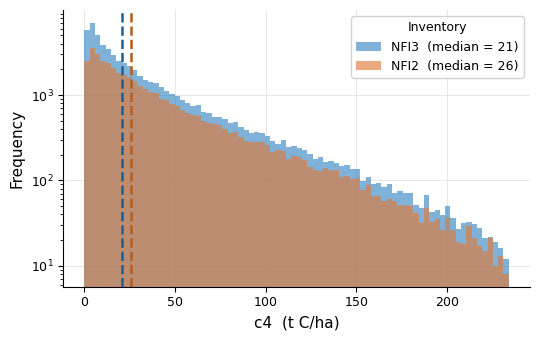

hist_c4 guardada.


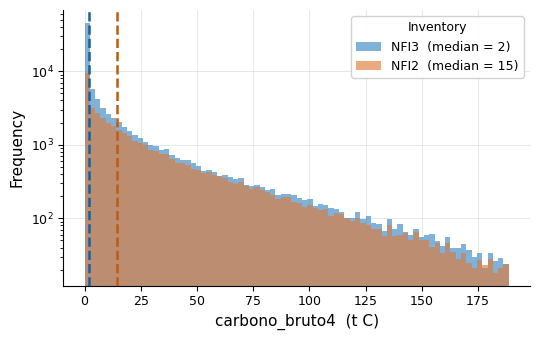

hist_carbono_bruto4 guardada.


In [6]:
import matplotlib.patches as mpatches

# ── Paleta ───────────────────────────────────────────────────────────
C2  = '#e07b39'
C3  = '#3a88c5'
C2d = '#b85c1a'
C3d = '#1e5f91'

_FIG_DIR = BASE / 'figures/EDA'
_FIG_DIR.mkdir(parents=True, exist_ok=True)

_vars = [
    ('c4',             'c4',             't C/ha', 80, 'hist_c4'),
    ('carbono_bruto4', 'carbono_bruto4', 't C',    80, 'hist_carbono_bruto4'),
]

for var, lbl, unit, nbins, fname in _vars:
    df_v  = _apply_training_filter(df_raw, var)[['ifn_id', var]]
    x_max = df_v[var].quantile(0.995)

    fig, ax = plt.subplots(figsize=(5.5, 3.5))

    for ifn_id, c, cd, name in [(3, C3, C3d, 'NFI3'), (2, C2, C2d, 'NFI2')]:
        data = df_v.loc[df_v['ifn_id'] == ifn_id, var]
        med  = data.median()
        ax.hist(data, bins=nbins, range=(0, x_max),
                color=c, alpha=0.65, edgecolor='none', zorder=2,
                label=f'{name}  (median = {med:.0f})')
        ax.axvline(med, color=cd, linewidth=1.8, linestyle='--', zorder=4)

    ax.set_yscale('log')
    ax.set_xlabel(f'{lbl}  ({unit})', fontsize=11)
    ax.set_ylabel('Frequency', fontsize=11)
    ax.tick_params(labelsize=9)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(axis='both', color='#dddddd', linewidth=0.5, zorder=0)
    ax.set_axisbelow(True)
    ax.legend(fontsize=9, framealpha=0.88, edgecolor='#cccccc',
              title='Inventory', title_fontsize=9)

    fig.tight_layout()
    fig.savefig(_FIG_DIR / f'{fname}.pdf', bbox_inches='tight')
    fig.savefig(_FIG_DIR / f'{fname}.png', dpi=200, bbox_inches='tight')
    plt.show()
    print(f'{fname} guardada.')

## Distribución del periodo entre inventarios

In [7]:
# ── Estilo para paper ────────────────────────────────────────────────
_RC = {
    'font.family'      : 'serif',
    'font.serif'       : ['Computer Modern Roman', 'Times New Roman', 'DejaVu Serif'],
    'font.size'        : 9,
    'axes.labelsize'   : 10,
    'xtick.labelsize'  : 8.5,
    'ytick.labelsize'  : 8.5,
    'legend.fontsize'  : 9,
    'legend.framealpha': 0.9,
    'axes.linewidth'   : 0.7,
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'xtick.major.size' : 3,
    'ytick.major.size' : 3,
    'axes.spines.top'  : False,
    'axes.spines.right': False,
}

# ── Paleta ──────────────────────────────────────────────────────────
C_IFN34  = '#2d6a4f'   # verde profundo — IFN3→IFN4
C_IFN23  = '#1d4e89'   # azul profundo  — IFN2→IFN3
C_EDGE   = 'white'     # separador entre barras

FIG_DIR = BASE / 'figures/EDA'
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ── Preparar datos ───────────────────────────────────────────────────
_dp = df_raw[['periodo', 'ifn_id']].dropna(subset=['periodo']).copy()
_dp['periodo'] = _dp['periodo'].astype(int)

_c34 = _dp[_dp['ifn_id'] == 3]['periodo'].value_counts().sort_index()
_c23 = _dp[_dp['ifn_id'] == 2]['periodo'].value_counts().sort_index()

_all_x   = sorted(set(_c34.index) | set(_c23.index))
_c34_all = _c34.reindex(_all_x, fill_value=0)
_c23_all = _c23.reindex(_all_x, fill_value=0)

def _style_ax(ax, xticks, step=2):
    """Aplica estilo común: cuadrícula, formato y etiquetas del eje X."""
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{int(v):,}'))
    ax.yaxis.set_tick_params(which='both', length=0)
    ax.grid(axis='y', color='#cccccc', linewidth=0.5, zorder=0)
    ax.set_axisbelow(True)
    # Tick en cada bin, etiqueta solo cada `step` años
    ax.set_xticks(xticks)
    ax.set_xticklabels([str(x) if x % step == 0 else '' for x in xticks])
    ax.set_xlabel('Number of years')
    ax.set_ylabel('Number of records')

In [8]:
# Celda eliminada — la figura de IFN3–IFN4 por separado se integra en la figura combinada

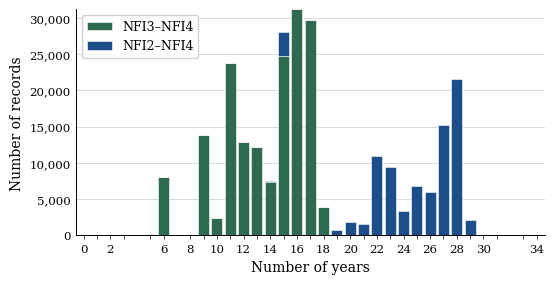

Figura guardada.


In [9]:
with plt.rc_context(_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.8))

    ax.bar(_all_x, _c34_all,
           color=C_IFN34, edgecolor=C_EDGE, linewidth=0.4, width=0.82,
           zorder=2, label='NFI3\u2013NFI4')
    ax.bar(_all_x, _c23_all, bottom=_c34_all,
           color=C_IFN23, edgecolor=C_EDGE, linewidth=0.4, width=0.82,
           zorder=2, label='NFI2\u2013NFI4')

    _style_ax(ax, _all_x, step=2)
    ax.set_xlim(min(_all_x) - 0.6, max(_all_x) + 0.6)
    ax.legend(loc='upper left', frameon=True, edgecolor='#cccccc')

    fig.tight_layout(pad=0.6)
    fig.savefig(FIG_DIR / 'hist_periodo.pdf', bbox_inches='tight')
    fig.savefig(FIG_DIR / 'hist_periodo.png', dpi=200, bbox_inches='tight')
    plt.show()
    print('Figura guardada.')

## Distribución de variables objetivo por periodo agrupado

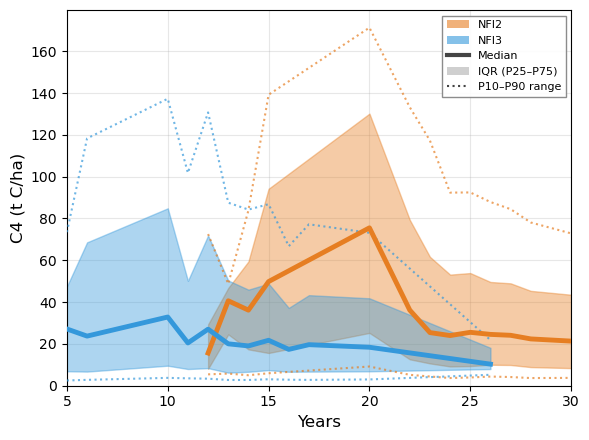

ribbon_c4 guardada.


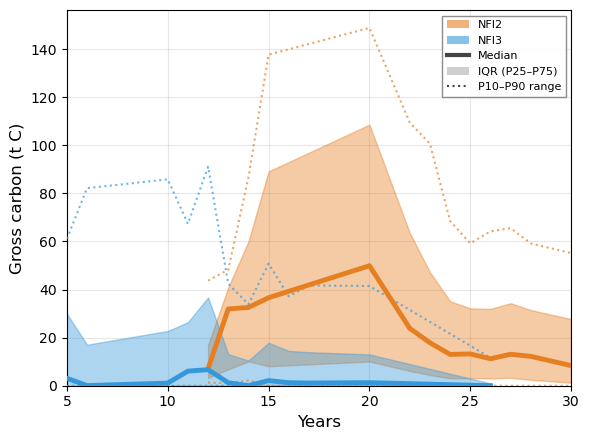

ribbon_carbono_bruto4 guardada.


In [10]:
from matplotlib.lines import Line2D

_band_vars = [
    ('c4',             'C4',            't C/ha', 'ribbon_c4'),
    ('carbono_bruto4', 'Gross carbon', 't C',    'ribbon_carbono_bruto4'),
]

_c_ifn2 = '#e67e22'
_c_ifn3 = '#3498db'

for var, lbl, unit, fname in _band_vars:
    df_v = _apply_training_filter(df_raw, var)[['ifn_id', 'periodo_agrupado', var]].dropna()

    fig, ax = plt.subplots(figsize=(6, 4.5))

    for ifn_id, color, name in [(2, _c_ifn2, 'NFI2'), (3, _c_ifn3, 'NFI3')]:
        sub = df_v[df_v['ifn_id'] == ifn_id].groupby('periodo_agrupado')[var]
        stats = sub.agg(
            p10=lambda x: x.quantile(0.10),
            p25=lambda x: x.quantile(0.25),
            p50=lambda x: x.quantile(0.50),
            p75=lambda x: x.quantile(0.75),
            p90=lambda x: x.quantile(0.90),
            count='count',
        )
        stats = stats[stats['count'] >= 5].sort_index()
        if len(stats) < 2:
            continue
        x = stats.index.values

        ax.fill_between(x, stats['p25'], stats['p75'], alpha=0.40, color=color, zorder=2)
        ax.plot(x, stats['p50'], color=color, linewidth=3.5, zorder=5)
        ax.plot(x, stats['p10'], color=color, linewidth=1.5, linestyle=':', alpha=0.7, zorder=3)
        ax.plot(x, stats['p90'], color=color, linewidth=1.5, linestyle=':', alpha=0.7, zorder=3)

    ax.set_xlabel('Years', fontsize=12)
    ax.set_ylabel(f'{lbl} ({unit})', fontsize=12)
    ax.set_xlim(5, 30)
    ax.set_ylim(bottom=0)
    ax.grid(True, alpha=0.3)

    _legend_h = [
        mpatches.Patch(facecolor=_c_ifn2, alpha=0.6, label='NFI2'),
        mpatches.Patch(facecolor=_c_ifn3, alpha=0.6, label='NFI3'),
        Line2D([0], [0], color='#444444', lw=3, label='Median'),
        mpatches.Patch(facecolor='#888888', alpha=0.4, label='IQR (P25\u2013P75)'),
        Line2D([0], [0], color='#444444', lw=1.5, ls=':', label='P10\u2013P90 range'),
    ]
    ax.legend(handles=_legend_h, loc='upper right', frameon=True,
              edgecolor='gray', fontsize=8, fancybox=False, framealpha=0.9)

    fig.tight_layout()
    fig.savefig(_FIG_DIR / f'{fname}.pdf', bbox_inches='tight')
    fig.savefig(_FIG_DIR / f'{fname}.png', dpi=300, bbox_inches='tight')
    plt.show()
    print(f'{fname} guardada.')

### Sin filtro de entrenamiento (datos brutos por IFN)

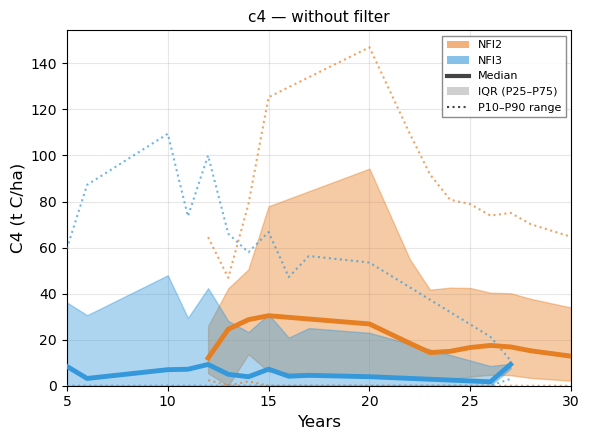

c4 sin filtro.


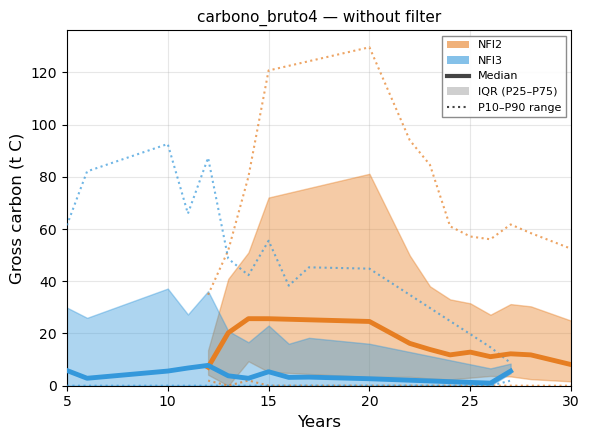

carbono_bruto4 sin filtro.


In [11]:
for var, lbl, unit, fname in _band_vars:
    df_v = df_raw[df_raw[var].notna()][['ifn_id', 'periodo_agrupado', var]].dropna()

    fig, ax = plt.subplots(figsize=(6, 4.5))

    for ifn_id, color, name in [(2, _c_ifn2, 'NFI2'), (3, _c_ifn3, 'NFI3')]:
        sub = df_v[df_v['ifn_id'] == ifn_id].groupby('periodo_agrupado')[var]
        stats = sub.agg(
            p10=lambda x: x.quantile(0.10),
            p25=lambda x: x.quantile(0.25),
            p50=lambda x: x.quantile(0.50),
            p75=lambda x: x.quantile(0.75),
            p90=lambda x: x.quantile(0.90),
            count='count',
        )
        stats = stats[stats['count'] >= 5].sort_index()
        if len(stats) < 2:
            continue
        x = stats.index.values

        ax.fill_between(x, stats['p25'], stats['p75'], alpha=0.40, color=color, zorder=2)
        ax.plot(x, stats['p50'], color=color, linewidth=3.5, zorder=5)
        ax.plot(x, stats['p10'], color=color, linewidth=1.5, linestyle=':', alpha=0.7, zorder=3)
        ax.plot(x, stats['p90'], color=color, linewidth=1.5, linestyle=':', alpha=0.7, zorder=3)

    ax.set_xlabel('Years', fontsize=12)
    ax.set_ylabel(f'{lbl} ({unit})', fontsize=12)
    ax.set_xlim(5, 30)
    ax.set_ylim(bottom=0)
    ax.grid(True, alpha=0.3)
    ax.set_title(f'{var} — without filter', fontsize=11)

    ax.legend(handles=_legend_h, loc='upper right', frameon=True,
              edgecolor='gray', fontsize=8, fancybox=False, framealpha=0.9)

    fig.tight_layout()
    plt.show()
    print(f'{var} sin filtro.')